# Lab 10: Fourier Series and Fourier Analysis

**Fourier analysis** reveals the hidden frequency content of a signal by decomposing it into sinusoidal components. Every periodic signal can be written as a sum of sines and cosines — each with its own **frequency**, **amplitude**, and **phase**.

## Learning Objectives

By the end of this session, you will be able to:
- Explain the difference between the **time domain** and **frequency domain**
- Compute **Fourier series coefficients** $A_0$, $A_k$, $B_k$ from $N$ discrete data points
- Use `scipy.fft.fft` to compute the **Discrete Fourier Transform (DFT)**
- Interpret and plot the **one-sided power spectrum** $P_k = |Y_k|^2$
- Apply a **low-pass filter** to remove noise by zeroing high-frequency DFT components
- Explain the **Nyquist frequency** and its role in signal sampling

## Session Outline

| # | Topic |  
|---|-------| 
| 1 | Introduction: Time vs. Frequency Domain |  
| 2 | Fourier Series |  
| 3 | Discrete Fourier Transform |  
| 4 | Power Spectrum |  
| 5 | Signal Filtering and Noise Removal |  
| 6 | Engineering Application: Vibration Analysis | 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, ifft

---
## 1. Introduction: Time vs. Frequency Domain

The same signal can be described in two complementary ways:

| Domain | Axis | Question answered |
|--------|------|-------------------|
| **Time domain** | $y$ vs. $t$ | What is the signal value at time $t$? |
| **Frequency domain** | $\|Y_k\|$ vs. $f$ | What sinusoidal frequencies compose the signal? |

**Key insight:** Noise typically spreads across *all* frequencies with small amplitude, while true signal components appear at *specific* frequencies with large amplitude.

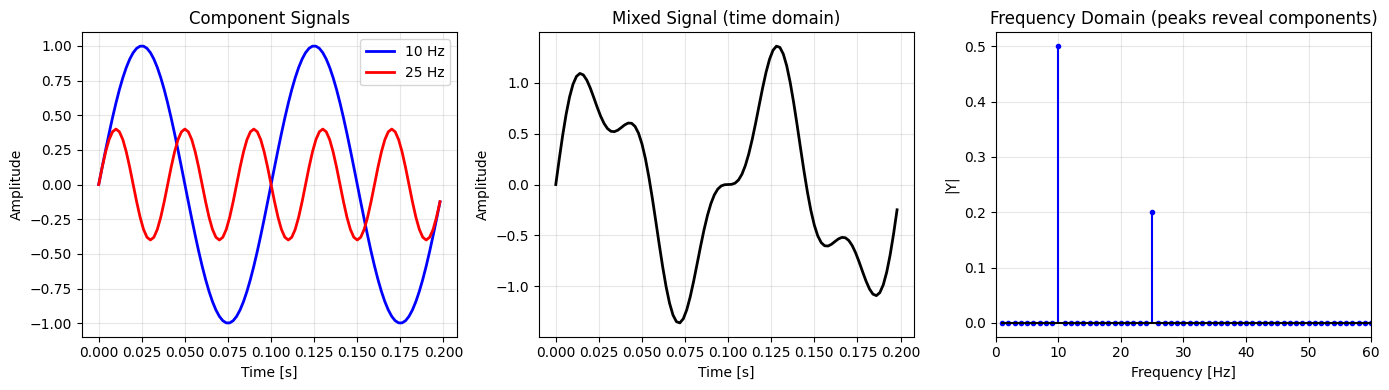

Two clear peaks at 10 Hz and 25 Hz — hidden in the noisy time-domain plot!


In [2]:
# Motivation: decompose a signal into two sinusoids
fs_demo = 500          # sampling rate [Hz]
t_demo  = np.linspace(0, 1, fs_demo, endpoint=False)

f1, A1_d = 10, 1.0    # first component: 10 Hz, amplitude 1
f2, A2_d = 25, 0.4    # second component: 25 Hz, amplitude 0.4

s1 = A1_d * np.sin(2*np.pi*f1*t_demo)
s2 = A2_d * np.sin(2*np.pi*f2*t_demo)
s  = s1 + s2

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(t_demo[:100], s1[:100], 'b-', lw=2, label=f'{f1} Hz')
axes[0].plot(t_demo[:100], s2[:100], 'r-', lw=2, label=f'{f2} Hz')
axes[0].set(xlabel='Time [s]', ylabel='Amplitude', title='Component Signals')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(t_demo[:100], s[:100], 'k-', lw=2)
axes[1].set(xlabel='Time [s]', ylabel='Amplitude', title='Mixed Signal (time domain)')
axes[1].grid(True, alpha=0.3)

Y_demo = fft(s) / fs_demo
freqs_demo = np.arange(fs_demo) / 1.0   # 1 second total -> freq in Hz
n2_d = fs_demo // 2
axes[2].stem(freqs_demo[1:n2_d], np.abs(Y_demo[1:n2_d]),
             basefmt='k-', linefmt='b-', markerfmt='b.')
axes[2].set(xlabel='Frequency [Hz]', ylabel='|Y|',
            title='Frequency Domain (peaks reveal components)',
            xlim=[0, 60])
axes[2].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()
print('Two clear peaks at 10 Hz and 25 Hz — hidden in the noisy time-domain plot!')

---
## 2. Fourier Series

### 2.1 Continuous Fourier Series

For a periodic function with period $T$, the **Fourier series** is:
$$f(t) \approx A_0 + \sum_{k=1}^{K} \left[ A_k \cos(k\omega_0 t) + B_k \sin(k\omega_0 t) \right]$$

where $\omega_0 = 2\pi/T$ is the **fundamental angular frequency**.

### 2.2 Coefficients from $N$ Discrete Data Points

Given $N$ equally spaced data $(t_i, y_i)$ over one period:

| Coefficient | Formula |
|-------------|--------|
| DC offset | $A_0 = \dfrac{1}{N}\sum_{i=0}^{N-1} y_i$ |
| Cosine amp. | $A_k = \dfrac{2}{N}\sum_{i=0}^{N-1} y_i \cos(k\omega_0 t_i)$ |
| Sine amp. | $B_k = \dfrac{2}{N}\sum_{i=0}^{N-1} y_i \sin(k\omega_0 t_i)$ |

**Combined amplitude:** $C_k = \sqrt{A_k^2 + B_k^2}$ (total energy at frequency $k$)

<>:14: SyntaxWarning: invalid escape sequence '\c'
<>:14: SyntaxWarning: invalid escape sequence '\c'
/var/folders/h6/zwp2wx491171gj4gxbyf2x0c0000gn/T/ipykernel_99615/2413878447.py:14: SyntaxWarning: invalid escape sequence '\c'
  ax.plot(tt, f_true(tt), 'b-', lw=2, label='True signal: $1.7 + \cos(\omega_0 t + \pi/3)$')


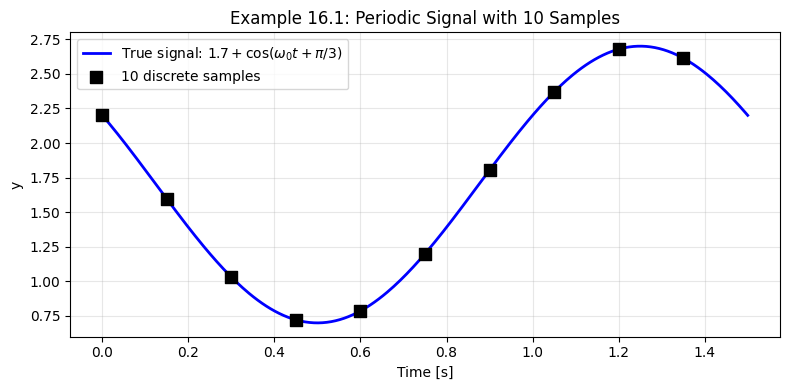

Period T = 1.5 s,  w0 = 4.1888 rad/s
N = 10 data points


In [3]:
# Example 16.1 — Fit a first-order Fourier series to 10 discrete data points
T  = 1.5                 # period [s]
w0 = 2*np.pi / T        # fundamental angular frequency [rad/s]

t_data = np.array([0, .15, .3, .45, .6, .75, .9, 1.05, 1.2, 1.35])
y_data = np.array([2.2, 1.595, 1.031, .722, .786, 1.2, 1.805, 2.369, 2.678, 2.614])

# True underlying signal: 1.7 + cos(w0*t + pi/3)
f_true = lambda t: 1.7 + np.cos(w0*t + np.pi/3)

tt = np.linspace(0, T, 300)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tt, f_true(tt), 'b-', lw=2, label='True signal: $1.7 + \cos(\omega_0 t + \pi/3)$')
ax.scatter(t_data, y_data, c='k', marker='s', s=80, zorder=5, label='10 discrete samples')
ax.set(xlabel='Time [s]', ylabel='y', title='Example 16.1: Periodic Signal with 10 Samples')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

print(f'Period T = {T} s,  w0 = {w0:.4f} rad/s')
print(f'N = {len(t_data)} data points')

In [4]:
def fourier_series_1(t, y, T):
    """
    Compute first-order Fourier series coefficients A0, A1, B1
    from N discrete equally-spaced data points.

    Parameters
    ----------
    t : array  -- time points
    y : array  -- signal values
    T : float  -- period

    Returns
    -------
    A0, A1, B1 : float
    """
    N  = len(y)
    w0 = 2*np.pi / T

    # --- COMPLETE ---
    A0 =          np.sum(y) / N
    A1 =          (2/N) * np.sum(y * np.cos(w0 * t))
    B1 =          (2/N) * np.sum(y * np.sin(w0 * t))
    # --- COMPLETE ---

    return A0, A1, B1

<!-- SOLUTION
A0 = np.sum(y) / N
A1 = (2/N) * np.sum(y * np.cos(w0 * t))
B1 = (2/N) * np.sum(y * np.sin(w0 * t))
-->

=== First-order Fourier Series Coefficients ===
A0 = 1.700000   (mean value, expected 1.7)
A1 = 0.499992   (cosine amplitude, expected  0.5)
B1 = -0.866137   (sine amplitude,   expected -0.866)
Combined amplitude C1 = sqrt(A1^2+B1^2) = 1.0001  (expected 1.0)


<>:24: SyntaxWarning: invalid escape sequence '\h'
<>:24: SyntaxWarning: invalid escape sequence '\h'
/var/folders/h6/zwp2wx491171gj4gxbyf2x0c0000gn/T/ipykernel_99615/3285014043.py:24: SyntaxWarning: invalid escape sequence '\h'
  ax.set(xlabel='Time [s]', ylabel='Residual $y_i - \hat{y}_i$',


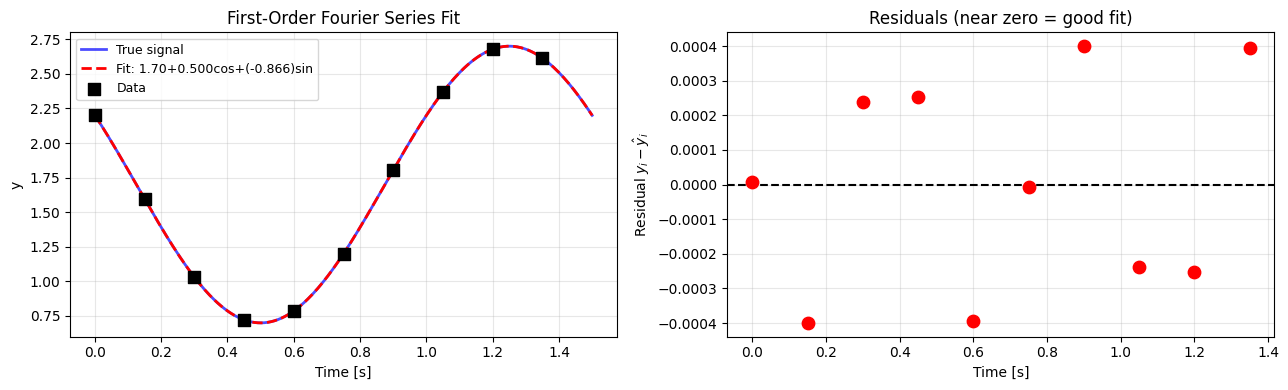

In [5]:
A0, A1, B1 = fourier_series_1(t_data, y_data, T)

print('=== First-order Fourier Series Coefficients ===')
print(f'A0 = {A0:.6f}   (mean value, expected 1.7)')
print(f'A1 = {A1:.6f}   (cosine amplitude, expected  0.5)')
print(f'B1 = {B1:.6f}   (sine amplitude,   expected -0.866)')
print(f'Combined amplitude C1 = sqrt(A1^2+B1^2) = {np.sqrt(A1**2+B1**2):.4f}  (expected 1.0)')

f_fit = lambda t: A0 + A1*np.cos(w0*t) + B1*np.sin(w0*t)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.plot(tt, f_true(tt), 'b-', lw=2, alpha=0.7, label='True signal')
ax.plot(tt, f_fit(tt),  'r--', lw=2, label=f'Fit: {A0:.2f}+{A1:.3f}cos+({B1:.3f})sin')
ax.scatter(t_data, y_data, c='k', marker='s', s=80, zorder=5, label='Data')
ax.set(xlabel='Time [s]', ylabel='y', title='First-Order Fourier Series Fit')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[1]
residuals = y_data - f_fit(t_data)
ax.scatter(t_data, residuals, c='r', s=80, zorder=5)
ax.axhline(0, color='k', lw=1.5, ls='--')
ax.set(xlabel='Time [s]', ylabel='Residual $y_i - \hat{y}_i$',
       title='Residuals (near zero = good fit)')
ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

### 2.3 Higher-Order Harmonics

With $N$ data points, up to $N/2$ harmonics can be resolved. Adding more terms reduces the residual:

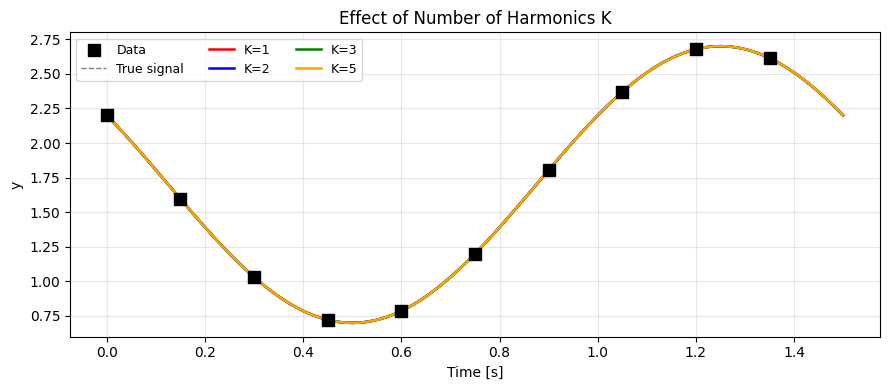

Note: with N=10 data points, max harmonics = N/2 = 5


In [6]:
def fourier_coeffs(t, y, T, K):
    """Compute Fourier coefficients A[0..K] and B[0..K] for K harmonics."""
    N  = len(y)
    w0 = 2*np.pi / T
    A  = np.zeros(K + 1)
    B  = np.zeros(K + 1)
    A[0] = np.sum(y) / N
    for k in range(1, K + 1):
        A[k] = (2.0/N) * np.sum(y * np.cos(k * w0 * t))
        B[k] = (2.0/N) * np.sum(y * np.sin(k * w0 * t))
    return A, B

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(t_data, y_data, c='k', marker='s', s=80, zorder=5, label='Data')
ax.plot(tt, f_true(tt), 'k--', lw=1, alpha=0.5, label='True signal')

for K, col in zip([1, 2, 3, 5], ['red', 'blue', 'green', 'orange']):
    A, B = fourier_coeffs(t_data, y_data, T, K)
    y_kfit = A[0] + sum(A[k]*np.cos(k*w0*tt) + B[k]*np.sin(k*w0*tt)
                        for k in range(1, K+1))
    ax.plot(tt, y_kfit, color=col, lw=1.8, label=f'K={K}')

ax.set(xlabel='Time [s]', ylabel='y', title='Effect of Number of Harmonics K')
ax.legend(ncol=3, fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()
print('Note: with N=10 data points, max harmonics = N/2 = 5')

**Exercise 2.1:** A temperature sensor records the following hourly data over one day ($T = 24$ hours).
Compute $A_0$, $A_1$, $B_1$ using `fourier_series_1`, plot the fit, and interpret $A_0$ physically.

=== Daily Temperature: First-Order Fourier Series ===
A0 = 20.3125 °C   (daily mean temperature)
A1 = -5.5327
B1 = -5.0102
C1 = sqrt(A1^2 + B1^2) = 7.4641 °C   (daily temperature swing amplitude)


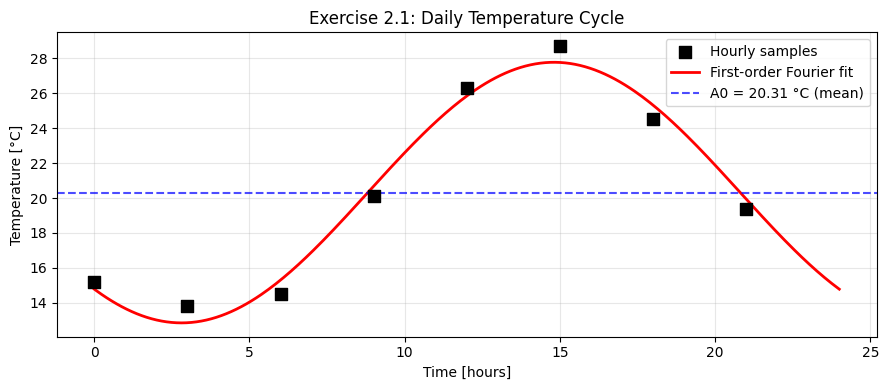


Physical interpretation:
  A0 = 20.31 °C is the *daily average* temperature (DC offset).
  C1 = 7.46 °C is half the peak-to-peak daily oscillation.
  Phase shift => the warmest hour occurs around t ≈ 14.8 h.


In [7]:
T_day  = 24.0   # hours
t_temp = np.array([0, 3, 6, 9, 12, 15, 18, 21], dtype=float)   # hours
y_temp = np.array([15.2, 13.8, 14.5, 20.1, 26.3, 28.7, 24.5, 19.4])  # Celsius

# --- YOUR CODE HERE ---
A0_t, A1_t, B1_t = fourier_series_1(t_temp, y_temp, T_day)
w0_t = 2*np.pi / T_day
C1_t = np.sqrt(A1_t**2 + B1_t**2)

print('=== Daily Temperature: First-Order Fourier Series ===')
print(f'A0 = {A0_t:.4f} °C   (daily mean temperature)')
print(f'A1 = {A1_t:.4f}')
print(f'B1 = {B1_t:.4f}')
print(f'C1 = sqrt(A1^2 + B1^2) = {C1_t:.4f} °C   (daily temperature swing amplitude)')

tt_t   = np.linspace(0, T_day, 300)
y_fit  = A0_t + A1_t*np.cos(w0_t*tt_t) + B1_t*np.sin(w0_t*tt_t)

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(t_temp, y_temp, c='k', marker='s', s=80, zorder=5, label='Hourly samples')
ax.plot(tt_t, y_fit, 'r-', lw=2, label='First-order Fourier fit')
ax.axhline(A0_t, color='b', ls='--', alpha=0.7, label=f'A0 = {A0_t:.2f} °C (mean)')
ax.set(xlabel='Time [hours]', ylabel='Temperature [°C]',
       title='Exercise 2.1: Daily Temperature Cycle')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

print(f'\nPhysical interpretation:')
print(f'  A0 = {A0_t:.2f} °C is the *daily average* temperature (DC offset).')
print(f'  C1 = {C1_t:.2f} °C is half the peak-to-peak daily oscillation.')
print(f'  Phase shift => the warmest hour occurs around t ≈ '
      f'{(np.arctan2(B1_t, A1_t) * T_day / (2*np.pi)) % T_day:.1f} h.')

---
## 3. Discrete Fourier Transform (DFT)

While Fourier series requires knowing the period $T$ in advance, the **DFT** handles any finite signal.

### 3.1 Sampling Parameters

| Parameter | Symbol | Formula | Meaning |
|-----------|--------|---------|--------|
| Sampling interval | $\Delta t$ | given | Time between samples |
| Sampling frequency | $f_s$ | $1/\Delta t$ | Samples per second |
| Total record length | $T_{\text{total}}$ | $N \cdot \Delta t$ | Duration of signal |
| Frequency resolution | $\Delta f$ | $1/T_{\text{total}}$ | Smallest distinguishable frequency |
| **Nyquist frequency** | $f_{\text{Nyq}}$ | $f_s/2$ | **Maximum detectable frequency** |

> **Nyquist theorem:** To detect a frequency $f$, you must sample at $f_s \geq 2f$.
> Frequencies above $f_{\text{Nyq}}$ appear as false lower-frequency signals (**aliasing**).

### 3.2 Normalized DFT

`scipy.fft.fft(y)` returns $N$ complex coefficients. After normalization:
$$Y_k = \frac{1}{N}\sum_{j=0}^{N-1} y_j\, e^{-2\pi i k j / N}
       \quad\Longrightarrow\quad \texttt{Y = fft(y) / N}$$

- $Y[0]$ = mean value (DC component)
- $Y[1 \ldots N/2]$ = positive-frequency components
- $Y[N/2+1 \ldots N-1]$ = mirror of negative frequencies (redundant for real signals)

=== Sampling Parameters (Ex. 16.3) ===
N                = 8
dt               = 0.02 s
fs               = 50.0 Hz
T_total          = 0.16 s
Nyquist freq     = 25.0 Hz
Freq resolution  = 6.2500 Hz
Lowest freq      = 6.2500 Hz  (= 1/T_total)


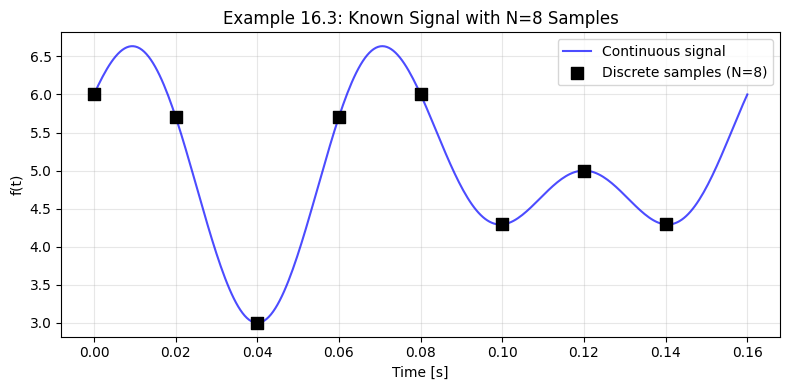

In [8]:
# Example 16.3 — Known signal: f(t) = 5 + cos(2pi*12.5*t) + sin(2pi*18.75*t)
n_dft     = 8
dt_dft    = 0.02          # s
fs_dft    = 1.0 / dt_dft  # Hz
T_total   = n_dft * dt_dft
t_dft     = np.arange(n_dft) / fs_dft

freq1_ex  = 12.5          # Hz
freq2_ex  = 18.75         # Hz
func_ex   = lambda t: 5 + np.cos(2*np.pi*freq1_ex*t) + np.sin(2*np.pi*freq2_ex*t)
y_dft     = func_ex(t_dft)

print('=== Sampling Parameters (Ex. 16.3) ===')
print(f'N                = {n_dft}')
print(f'dt               = {dt_dft} s')
print(f'fs               = {fs_dft} Hz')
print(f'T_total          = {T_total} s')
print(f'Nyquist freq     = {fs_dft/2} Hz')
print(f'Freq resolution  = {1/T_total:.4f} Hz')
print(f'Lowest freq      = {1/T_total:.4f} Hz  (= 1/T_total)')

tt_ex = np.linspace(0, T_total, 300)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tt_ex, func_ex(tt_ex), 'b-', lw=1.5, alpha=0.7, label='Continuous signal')
ax.scatter(t_dft, y_dft, c='k', marker='s', s=80, zorder=5, label='Discrete samples (N=8)')
ax.set(xlabel='Time [s]', ylabel='f(t)', title='Example 16.3: Known Signal with N=8 Samples')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [9]:
def compute_dft(y, dt):
    """
    Compute the normalized DFT of signal y.

    Parameters
    ----------
    y  : array  -- time-domain signal (N points)
    dt : float  -- sampling interval [s]

    Returns
    -------
    Y    : complex array  -- normalized DFT coefficients  Y = fft(y)/N
    freq : array          -- frequency array [Hz] for indices 1..N-1
    fs   : float          -- sampling frequency [Hz]
    """
    N       = len(y)
    fs      = 1.0 / dt
    T_total = N * dt

    # --- COMPLETE ---
    Y    =       fft(y) / N
    freq =       np.arange(1, N) / T_total
    # --- COMPLETE ---

    return Y, freq, fs

<!-- SOLUTION
Y    = fft(y) / N
freq = np.arange(1, N) / T_total
-->

In [10]:
Y_dft, freq_dft, _ = compute_dft(y_dft, dt_dft)

print('=== DFT Coefficients Y[k] ===')
print(f'{"k":<3} {"freq [Hz]":>10} {"Re(Y[k])":>14} {"Im(Y[k])":>14} {"|Y[k]|":>12}')
print('-' * 58)
for k in range(n_dft):
    f_k = k / T_total
    print(f'{k:<3} {f_k:>10.4f} {Y_dft[k].real:>14.6f} {Y_dft[k].imag:>14.6f} {abs(Y_dft[k]):>12.6f}')

print()
print(f'Y[0].real = {Y_dft[0].real:.4f}  <- mean (expected 5)')
print(f'Y[2].real = {Y_dft[2].real:.4f}  <- cosine at {freq_dft[1]:.2f} Hz (expected 0.5)')
print(f'Y[3].imag = {Y_dft[3].imag:.4f}  <- sine   at {freq_dft[2]:.2f} Hz (expected -0.5)')

=== DFT Coefficients Y[k] ===
k    freq [Hz]       Re(Y[k])       Im(Y[k])       |Y[k]|
----------------------------------------------------------
0       0.0000       5.000000      -0.000000     5.000000
1       6.2500       0.000000       0.000000     0.000000
2      12.5000       0.500000      -0.000000     0.500000
3      18.7500      -0.000000      -0.500000     0.500000
4      25.0000       0.000000      -0.000000     0.000000
5      31.2500      -0.000000       0.500000     0.500000
6      37.5000       0.500000       0.000000     0.500000
7      43.7500       0.000000      -0.000000     0.000000

Y[0].real = 5.0000  <- mean (expected 5)
Y[2].real = 0.5000  <- cosine at 12.50 Hz (expected 0.5)
Y[3].imag = -0.5000  <- sine   at 18.75 Hz (expected -0.5)


---
## 4. Power Spectrum

The **power spectrum** shows how signal energy is distributed across frequencies.

### 4.1 Definition

For the **one-sided** spectrum (frequencies from $\Delta f$ to Nyquist):
$$P_k = |Y_k|^2 \quad \text{for } k = 1, 2, \ldots, N/2$$

- Large $P_k$: strong sinusoidal component at frequency $f_k$
- Small $P_k$: no significant component there
- Only use $k = 1 \ldots N/2$ because $Y[N/2+1 \ldots N-1]$ mirrors the positive-frequency half

### 4.2 Interpreting the Spectrum

| Feature | Interpretation |
|---------|----------------|
| Sharp peak at $f_k$ | Signal has a strong periodic component at $f_k$ Hz |
| Broad, flat floor | Random noise (white noise spreads equally over all frequencies) |
| Peak at $f = 0$ | DC offset (non-zero mean) |

<!-- fP  =       freq[:n2]             #frequencies from delta_f to Nyquist
Pyy =       np.abs(Y[1:n2+1])**2  #power at each positive frequency -->

In [11]:
def power_spectrum(Y, freq, fs):
    """
    Compute the one-sided power spectrum from normalized DFT coefficients Y.

    Parameters
    ----------
    Y    : complex array -- normalized DFT (Y = fft(y)/N), length N
    freq : array         -- frequency array for indices 1..N-1
    fs   : float         -- sampling frequency [Hz]

    Returns
    -------
    fP  : array -- frequency values for one-sided spectrum
    Pyy : array -- power at each frequency (|Y_k|^2)
    """
    N  = len(Y)
    n2 = N // 2

    # --- COMPLETE ---
    fP  = freq[:n2]            #frequencies from delta_f to Nyquist
    Pyy = np.abs(Y[1:n2+1])**2 #power at each positive frequency
    # --- COMPLETE ---

    return fP, Pyy

<!-- SOLUTION
fP  = freq[:n2]
Pyy = np.abs(Y[1:n2+1])**2
-->

=== One-Sided Power Spectrum (Ex. 16.3) ===
   Freq [Hz]    Power |Yk|^2
------------------------------
      6.2500      0.00000000
     12.5000      0.25000000  <-- peak
     18.7500      0.25000000  <-- peak
     25.0000      0.00000000


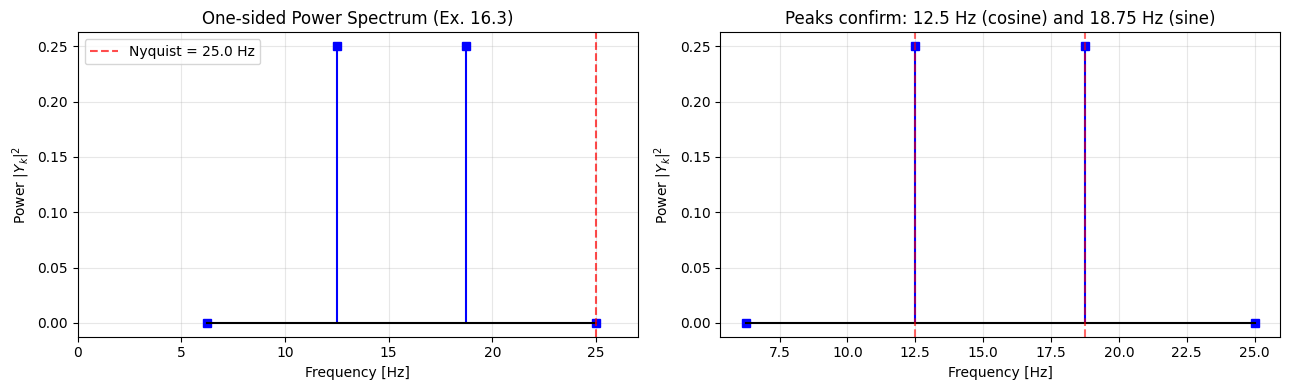

Both signal frequencies are clearly identified as peaks.


In [12]:
fP_dft, Pyy_dft = power_spectrum(Y_dft, freq_dft, fs_dft)

print('=== One-Sided Power Spectrum (Ex. 16.3) ===')
print(f'{"Freq [Hz]":>12}  {"Power |Yk|^2":>14}')
print('-' * 30)
for f_k, p_k in zip(fP_dft, Pyy_dft):
    tag = '  <-- peak' if p_k > 0.1 else ''
    print(f'{f_k:>12.4f}  {p_k:>14.8f}{tag}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.stem(fP_dft, Pyy_dft, basefmt='k-', linefmt='b-', markerfmt='bs')
ax.axvline(fs_dft/2, color='r', ls='--', alpha=0.7, label=f'Nyquist = {fs_dft/2} Hz')
ax.set(xlabel='Frequency [Hz]', ylabel='Power $|Y_k|^2$',
       title='One-sided Power Spectrum (Ex. 16.3)',
       xlim=[0, fs_dft/2 + 2])
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.stem(fP_dft, Pyy_dft, basefmt='k-', linefmt='b-', markerfmt='bs')
ax.set(xlabel='Frequency [Hz]', ylabel='Power $|Y_k|^2$',
       title=f'Peaks confirm: 12.5 Hz (cosine) and 18.75 Hz (sine)')
for f_peak in [12.5, 18.75]:
    ax.axvline(f_peak, color='r', ls='--', alpha=0.6)
ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()
print('Both signal frequencies are clearly identified as peaks.')

**Exercise 4.1:** Return to Example 16.1 (the 10-point periodic data, $T=1.5$ s).
1. Compute the DFT using `compute_dft` with `dt = 0.15` s.
2. Plot the power spectrum.
3. Identify the dominant frequency in Hz. Does it match $\omega_0/(2\pi)$?

=== Power Spectrum for Example 16.1 ===
   Freq [Hz]    Power |Yk|^2
------------------------------
      0.6667        0.250047  <-- peak
      1.3333        0.000000
      2.0000        0.000000
      2.6667        0.000000
      3.3333        0.000000

Dominant frequency from spectrum : 0.6667 Hz
Expected (1/T = w0/(2*pi))       : 0.6667 Hz
Match? YES


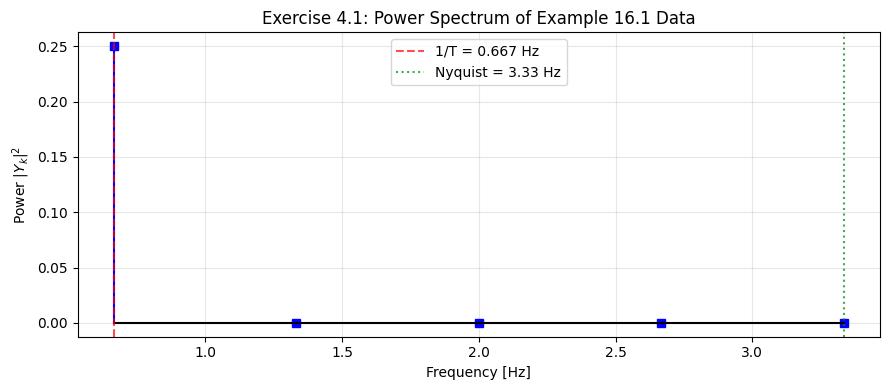

In [13]:
# --- YOUR CODE HERE ---
# Example 16.1 data:  T = 1.5 s, N = 10, dt = 0.15 s
dt_ex41 = 0.15
Y_ex41, freq_ex41, fs_ex41 = compute_dft(y_data, dt_ex41)
fP_ex41, Pyy_ex41 = power_spectrum(Y_ex41, freq_ex41, fs_ex41)

print('=== Power Spectrum for Example 16.1 ===')
print(f'{"Freq [Hz]":>12}  {"Power |Yk|^2":>14}')
print('-' * 30)
for f_k, p_k in zip(fP_ex41, Pyy_ex41):
    tag = '  <-- peak' if p_k > 0.05 else ''
    print(f'{f_k:>12.4f}  {p_k:>14.6f}{tag}')

dom_freq = fP_ex41[np.argmax(Pyy_ex41)]
expected = 1.0 / T   # = w0 / (2*pi)

print()
print(f'Dominant frequency from spectrum : {dom_freq:.4f} Hz')
print(f'Expected (1/T = w0/(2*pi))       : {expected:.4f} Hz')
print(f'Match? {"YES" if np.isclose(dom_freq, expected) else "NO"}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.stem(fP_ex41, Pyy_ex41, basefmt='k-', linefmt='b-', markerfmt='bs')
ax.axvline(expected, color='r', ls='--', alpha=0.7,
           label=f'1/T = {expected:.3f} Hz')
ax.axvline(fs_ex41/2, color='g', ls=':', alpha=0.7,
           label=f'Nyquist = {fs_ex41/2:.2f} Hz')
ax.set(xlabel='Frequency [Hz]', ylabel='Power $|Y_k|^2$',
       title='Exercise 4.1: Power Spectrum of Example 16.1 Data')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

---
## 5. Signal Filtering and Noise Removal

### 5.1 The Idea

An **ideal low-pass filter** removes high-frequency noise:

1. Compute normalized DFT: `Y = fft(y) / N`
2. Zero out components above cutoff: `Y_filt[freq > f_cut] = 0`
3. Reconstruct with inverse DFT: `y_filt = real(ifft(Y_filt * N))`

**Why this works:**
- Real signal energy concentrates at **specific frequencies** with large $|Y_k|$
- Random noise spreads power **uniformly** across all frequencies with small $|Y_k|$
- The power spectrum reveals which frequencies are signal vs. noise

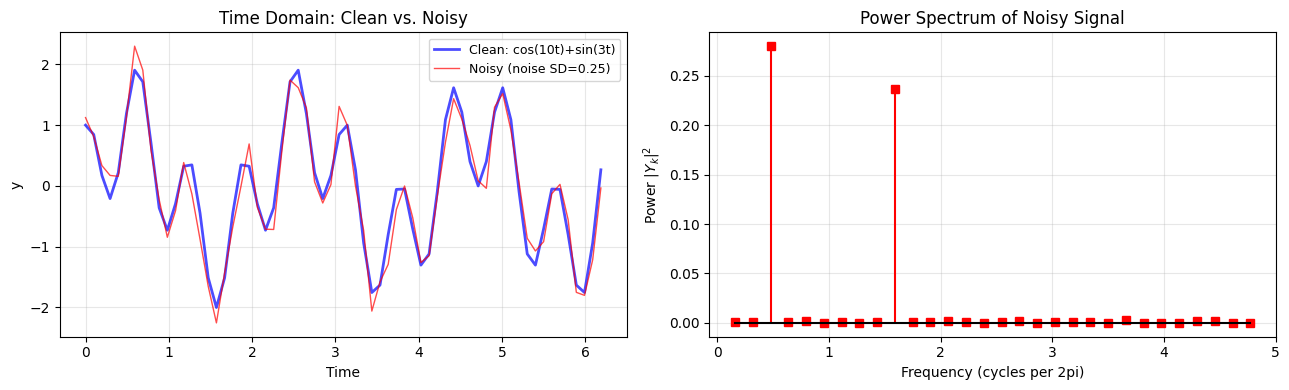

Two large peaks (at freq 3 and 10) above a noise floor.


In [14]:
# Problem 16.12 — noisy version of f(t) = cos(10t) + sin(3t)
np.random.seed(42)
n_noisy   = 64
t_noisy   = np.linspace(0, 2*np.pi, n_noisy, endpoint=False)
y_clean   = np.cos(10*t_noisy) + np.sin(3*t_noisy)
noise     = np.random.normal(0, 0.25, n_noisy)
y_noisy   = y_clean + noise

dt_noisy  = t_noisy[1] - t_noisy[0]
Y_noisy   = fft(y_noisy) / n_noisy
freq_noisy = np.arange(1, n_noisy) / (n_noisy * dt_noisy)
fP_n, Pyy_n = power_spectrum(Y_noisy, freq_noisy, 1/dt_noisy)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.plot(t_noisy, y_clean, 'b-', lw=2, label='Clean: cos(10t)+sin(3t)', alpha=0.7)
ax.plot(t_noisy, y_noisy, 'r-', lw=1, alpha=0.7, label='Noisy (noise SD=0.25)')
ax.set(xlabel='Time', ylabel='y', title='Time Domain: Clean vs. Noisy')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.stem(fP_n[:30], Pyy_n[:30], basefmt='k-', linefmt='r-', markerfmt='rs')
ax.set(xlabel='Frequency (cycles per 2pi)', ylabel='Power $|Y_k|^2$',
       title='Power Spectrum of Noisy Signal')
ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()
print('Two large peaks (at freq 3 and 10) above a noise floor.')

In [15]:
def lowpass_filter(y, dt, f_cut):
    """
    Apply an ideal low-pass filter to signal y.

    Parameters
    ----------
    y     : array -- noisy time-domain signal
    dt    : float -- sampling interval
    f_cut : float -- cutoff frequency (same units as 1/dt)

    Returns
    -------
    y_filt : array -- filtered signal (real)
    Y_filt : array -- filtered DFT coefficients
    """
    N       = len(y)
    T_total = N * dt

    # Step 1: normalized DFT
    Y = fft(y) / N

    # Frequency for each DFT index k = 0, 1, ..., N-1
    freq_all = np.arange(N) / T_total

    # Step 2: zero out indices where frequency exceeds f_cut
    Y_filt = Y.copy()
    # --- COMPLETE ---
    Y_filt[freq_all > f_cut] =       0.0 + 0.0j
    # --- COMPLETE ---

    # Step 3: inverse DFT and take real part
    y_filt = np.real(ifft(Y_filt * N))

    return y_filt, Y_filt

<!-- SOLUTION
Y_filt[freq_all > f_cut] = 0.0 + 0.0j
-->

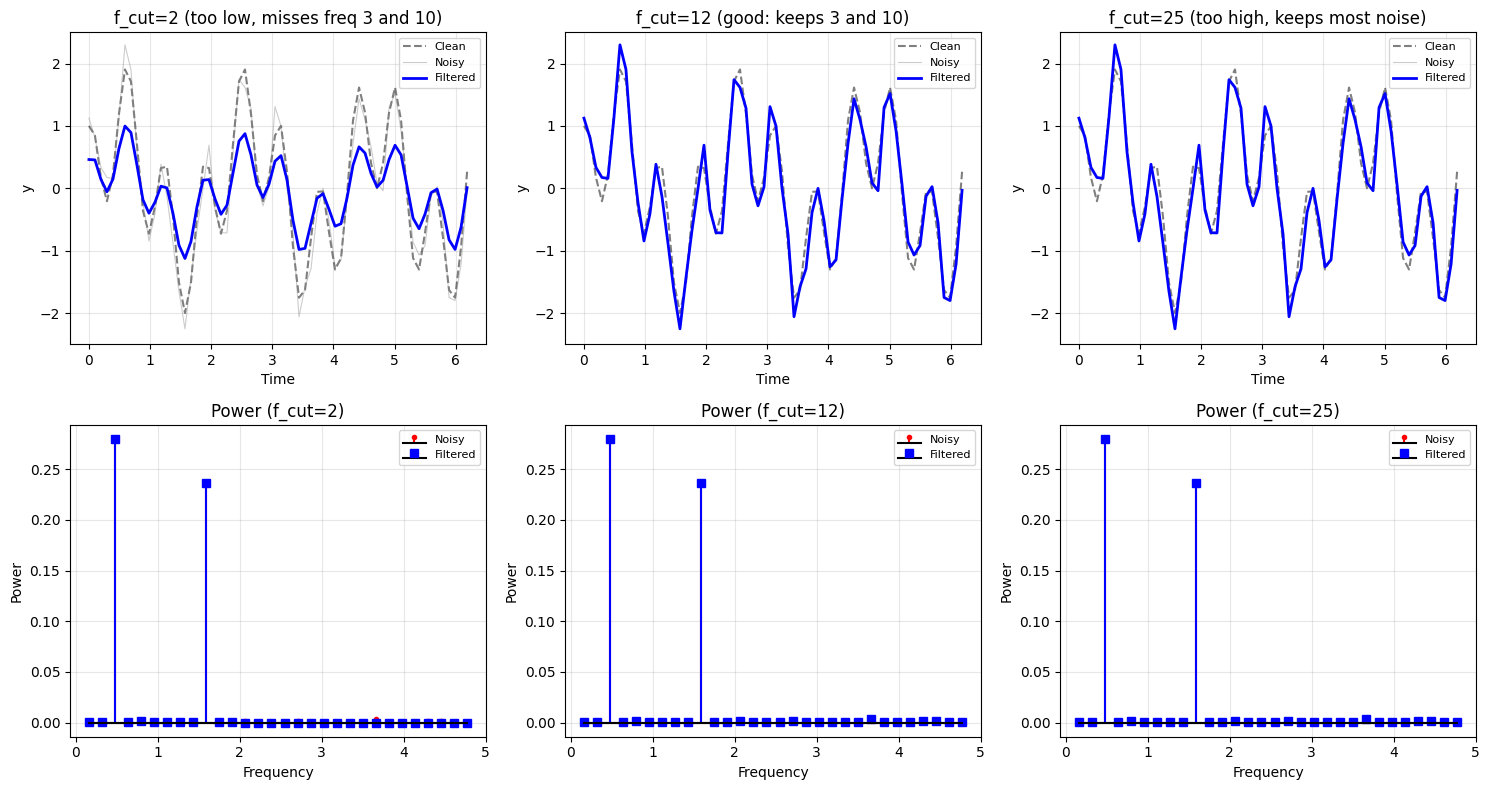

f_cut=12 recovers the two signal frequencies (3 and 10) while removing noise.


In [16]:
# Compare three cutoff frequencies
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
cutoffs = [2, 12, 25]
titles  = ['f_cut=2 (too low, misses freq 3 and 10)',
           'f_cut=12 (good: keeps 3 and 10)',
           'f_cut=25 (too high, keeps most noise)']

for idx, f_cut in enumerate(cutoffs):
    y_filt, Y_filt_i = lowpass_filter(y_noisy, dt_noisy, f_cut)

    # Top row: time domain
    ax = axes[0, idx]
    ax.plot(t_noisy, y_clean, 'k--', lw=1.5, alpha=0.5, label='Clean')
    ax.plot(t_noisy, y_noisy, 'gray', lw=0.8, alpha=0.4, label='Noisy')
    ax.plot(t_noisy, y_filt,  'b-',   lw=2,               label='Filtered')
    ax.set(xlabel='Time', ylabel='y', title=titles[idx], ylim=[-2.5, 2.5])
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

    # Bottom row: power spectrum comparison
    ax = axes[1, idx]
    fP_fi = np.arange(1, n_noisy) / (n_noisy * dt_noisy)
    n2_fi = n_noisy // 2
    Pyy_fi = np.abs(Y_filt_i[1:n2_fi+1])**2
    ax.stem(fP_n[:30], Pyy_n[:30],  basefmt='k-', linefmt='r-', markerfmt='r.', label='Noisy')
    ax.stem(fP_fi[:30], Pyy_fi[:30], basefmt='k-', linefmt='b-', markerfmt='bs', label='Filtered')
    ax.set(xlabel='Frequency', ylabel='Power', title=f'Power (f_cut={f_cut})')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()
print('f_cut=12 recovers the two signal frequencies (3 and 10) while removing noise.')

**Exercise 5.1:** Use the power spectrum to choose the best cutoff frequency, apply `lowpass_filter`,
then compute the **RMSE** against the clean signal:
$$\text{RMSE} = \sqrt{\frac{1}{N}\sum_{i=1}^N \left(y_{\text{clean},i} - y_{\text{filt},i}\right)^2}$$

Try several values of `f_cut` and report which minimizes RMSE.

=== RMSE vs cutoff frequency ===
 f_cut        RMSE
     2     0.50043
     5     0.50779
     8     0.52704
    10     0.22485  <-- best
    11     0.22762
    12     0.22762
    15     0.22762
    20     0.22762
    25     0.22762
    30     0.22762

Best cutoff: f_cut = 10 (cycles per 2pi)  ->  RMSE = 0.2248
Reason: keeps both signal peaks (at 3 and 10) but rejects most noise above 10.


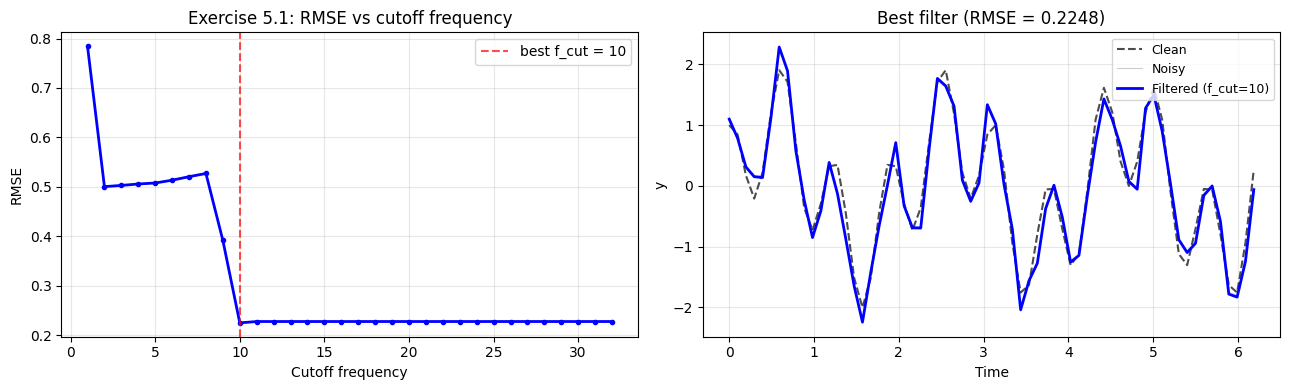

In [17]:
# --- YOUR CODE HERE ---
# 1. Examine the power spectrum to identify the noise floor
# 2. Choose f_cut between the last signal peak and the noise floor
# 3. Compute RMSE = sqrt(mean((y_clean - y_filt)**2))

# Step 1: spectrum already computed as (fP_n, Pyy_n) above.
# Signal peaks sit at frequencies 3 and 10 (cycles per 2pi); the noise floor lies below.

# Step 2: sweep f_cut and pick the value that minimizes RMSE.
cutoffs_test = np.arange(1, 33, 1)
rmse_list    = []
for f_c in cutoffs_test:
    y_f, _ = lowpass_filter(y_noisy, dt_noisy, f_c)
    rmse_list.append(np.sqrt(np.mean((y_clean - y_f)**2)))
rmse_arr  = np.array(rmse_list)
best_idx  = int(np.argmin(rmse_arr))
best_fcut = cutoffs_test[best_idx]
best_rmse = rmse_arr[best_idx]

# Compare a few representative cutoffs as a table
print('=== RMSE vs cutoff frequency ===')
print(f'{"f_cut":>6}  {"RMSE":>10}')
for f_c, r in zip(cutoffs_test, rmse_arr):
    if f_c in [2, 5, 8, 10, 11, 12, 15, 20, 25, 30]:
        mark = '  <-- best' if f_c == best_fcut else ''
        print(f'{f_c:>6}  {r:>10.5f}{mark}')

print(f'\nBest cutoff: f_cut = {best_fcut} (cycles per 2pi)  ->  RMSE = {best_rmse:.4f}')
print('Reason: keeps both signal peaks (at 3 and 10) but rejects most noise above 10.')

# Step 3: visualize the result
y_best, _ = lowpass_filter(y_noisy, dt_noisy, best_fcut)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.plot(cutoffs_test, rmse_arr, 'b.-', lw=2)
ax.axvline(best_fcut, color='r', ls='--', alpha=0.7,
           label=f'best f_cut = {best_fcut}')
ax.set(xlabel='Cutoff frequency', ylabel='RMSE',
       title='Exercise 5.1: RMSE vs cutoff frequency')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(t_noisy, y_clean, 'k--', lw=1.5, alpha=0.7, label='Clean')
ax.plot(t_noisy, y_noisy, 'gray', lw=0.8, alpha=0.4, label='Noisy')
ax.plot(t_noisy, y_best,  'b-',   lw=2, label=f'Filtered (f_cut={best_fcut})')
ax.set(xlabel='Time', ylabel='y',
       title=f'Best filter (RMSE = {best_rmse:.4f})')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

---
## 6. Engineering Application: Vibration Analysis

An **accelerometer** on a rotating machine records the sum of:
- **25 Hz**: fundamental shaft rotation (1500 RPM)
- **50 Hz**: second harmonic (imbalance)
- **60 Hz**: electrical interference from the power grid
- Random noise

**Goal:** Use the power spectrum to identify the machine's rotation frequency and isolate its vibration signature.

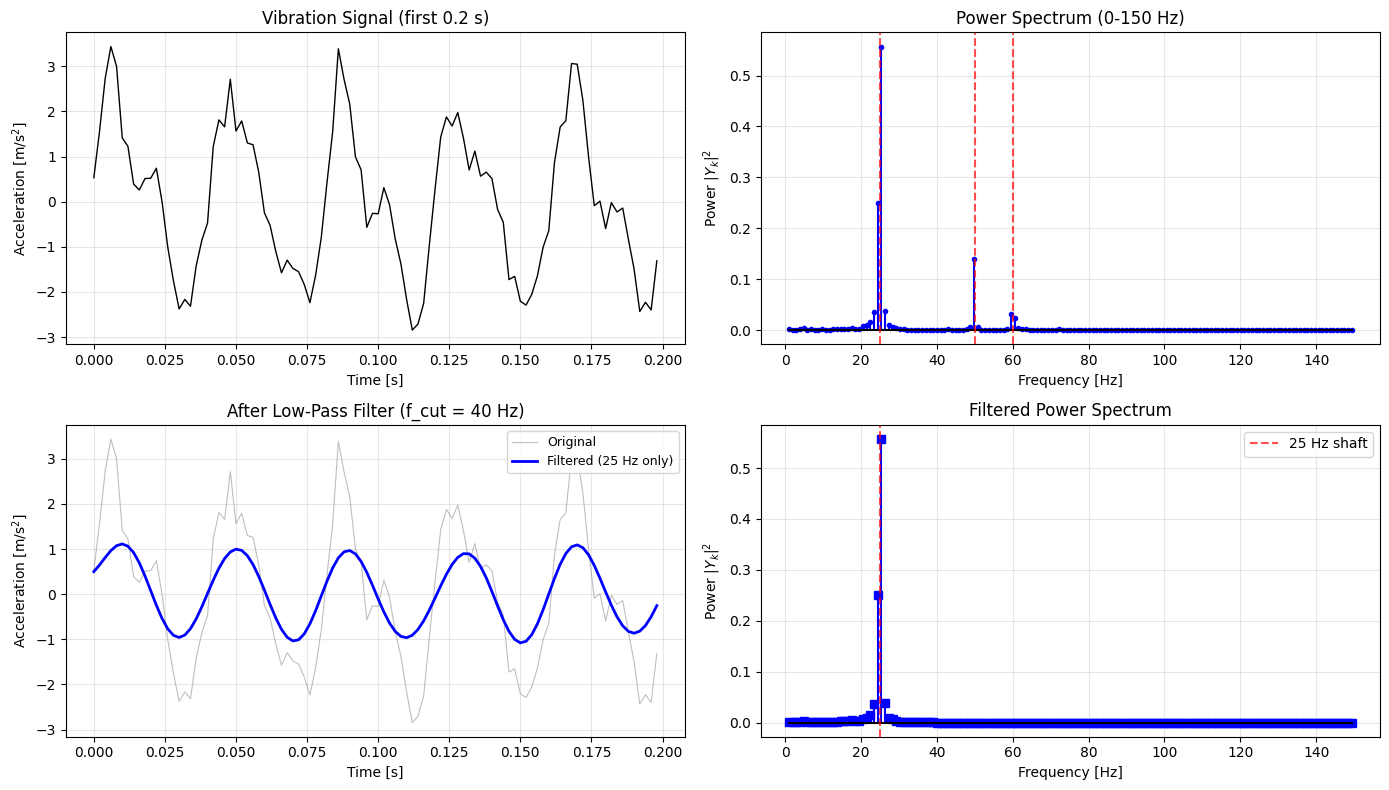

Dominant frequency: 25.4 Hz  ->  1523 RPM


In [18]:
np.random.seed(0)
fs_vib = 500                       # Hz
dt_vib = 1.0 / fs_vib
n_vib  = 512
t_vib  = np.arange(n_vib) * dt_vib

# Vibration signal: rotation (25 Hz) + harmonic (50 Hz) + interference (60 Hz) + noise
a_vib = (2.0 * np.sin(2*np.pi * 25 * t_vib) +
         0.8 * np.sin(2*np.pi * 50 * t_vib) +
         0.5 * np.sin(2*np.pi * 60 * t_vib) +
         0.3 * np.random.randn(n_vib))

Y_vib    = fft(a_vib) / n_vib
freq_vib = np.arange(1, n_vib) / (n_vib * dt_vib)
fP_vib, Pyy_vib = power_spectrum(Y_vib, freq_vib, fs_vib)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Time domain
ax = axes[0, 0]
ax.plot(t_vib[:100], a_vib[:100], 'k-', lw=1)
ax.set(xlabel='Time [s]', ylabel='Acceleration [m/s$^2$]',
       title='Vibration Signal (first 0.2 s)')
ax.grid(True, alpha=0.3)

# Full power spectrum
ax = axes[0, 1]
show = fP_vib < 150
ax.stem(fP_vib[show], Pyy_vib[show], basefmt='k-', linefmt='b-', markerfmt='b.')
ax.set(xlabel='Frequency [Hz]', ylabel='Power $|Y_k|^2$',
       title='Power Spectrum (0-150 Hz)')
for f_mark in [25, 50, 60]:
    ax.axvline(f_mark, color='r', ls='--', alpha=0.7)
ax.grid(True, alpha=0.3)

# Low-pass filter: keep only shaft rotation (< 40 Hz)
a_struct, Y_struct = lowpass_filter(a_vib, dt_vib, 40.0)
Pyy_struct = np.abs(Y_struct[1:n_vib//2+1])**2

# Filtered time domain
ax = axes[1, 0]
ax.plot(t_vib[:100], a_vib[:100],    'gray', lw=0.8, alpha=0.5, label='Original')
ax.plot(t_vib[:100], a_struct[:100], 'b-',   lw=2,               label='Filtered (25 Hz only)')
ax.set(xlabel='Time [s]', ylabel='Acceleration [m/s$^2$]',
       title='After Low-Pass Filter (f_cut = 40 Hz)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# Filtered power spectrum
ax = axes[1, 1]
ax.stem(fP_vib[show], Pyy_struct[show], basefmt='k-', linefmt='b-', markerfmt='bs')
ax.set(xlabel='Frequency [Hz]', ylabel='Power $|Y_k|^2$',
       title='Filtered Power Spectrum')
ax.axvline(25, color='r', ls='--', alpha=0.7, label='25 Hz shaft')
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

dom_freq = fP_vib[np.argmax(Pyy_vib[:len(fP_vib)//2])]
print(f'Dominant frequency: {dom_freq:.1f} Hz  ->  {dom_freq*60:.0f} RPM')

---
## Summary

### Key Formulas

| Quantity | Formula | Code |
|----------|---------|------|
| Angular freq. | $\omega_0 = 2\pi/T$ | `w0 = 2*np.pi/T` |
| DC coefficient | $A_0 = \frac{1}{N}\sum y_i$ | `A0 = np.sum(y)/N` |
| Cosine coeff. | $A_k = \frac{2}{N}\sum y_i \cos(k\omega_0 t_i)$ | `(2/N)*np.sum(y*np.cos(k*w0*t))` |
| Sine coeff. | $B_k = \frac{2}{N}\sum y_i \sin(k\omega_0 t_i)$ | `(2/N)*np.sum(y*np.sin(k*w0*t))` |
| Normalized DFT | $Y = \text{FFT}(y)/N$ | `Y = fft(y)/N` |
| Frequency array | $f_k = k / (N\Delta t)$ | `freq = np.arange(1,N)/(N*dt)` |
| Nyquist freq. | $f_{\text{Nyq}} = f_s/2$ | `f_nyq = 0.5/dt` |
| Power spectrum | $P_k = |Y_k|^2$ | `Pyy = np.abs(Y[1:n2+1])**2` |
| Low-pass filter | Zero $Y_k$ for $f_k > f_{\text{cut}}$, then IFFT | see `lowpass_filter` |

### Decision Guide

```
Do you know the period T?
  YES -> Fourier Series (fourier_coeffs)
         Use A0, Ak, Bk to fit f(t) = A0 + sum Ak*cos + Bk*sin
  NO  -> DFT: Y = fft(y)/N
         Frequency resolution = 1/(N*dt)
         Always check: is fs >= 2*f_max? (Nyquist)

After DFT:
  Identify dominant frequencies? -> Plot power spectrum |Y_k|^2
  Remove noise?                  -> Zero Y_k above f_cut, then ifft
  Reconstruct signal?            -> y_filt = real(ifft(Y_filt * N))
```

### Sampling Checklist

| Step | Check |
|------|-------|
| Choose $\Delta t$ | $f_s = 1/\Delta t \geq 2 \cdot f_{\max}$ (avoid aliasing) |
| Choose $N$ | Larger $N$ gives better frequency resolution $\Delta f = 1/(N\Delta t)$ |
| Identify peaks | Use power spectrum, look for values much above noise floor |
| Choose $f_{\text{cut}}$ | Between highest signal peak and noise floor |
| Validate | Compare RMSE of filtered vs. known clean signal |